In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


In [2]:
data=pd.read_csv("log2.csv")
df=pd.DataFrame(data)

In [3]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install pandas xlrd

Note: you may need to restart the kernel to use updated packages.


In [5]:
data

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18
...,...,...,...,...,...,...,...,...,...,...,...,...
65527,63691,80,13237,80,allow,314,192,122,6,15,4,2
65528,50964,80,13485,80,allow,4680740,67312,4613428,4675,77,985,3690
65529,54871,445,0,0,drop,70,70,0,1,0,1,0
65530,54870,445,0,0,drop,70,70,0,1,0,1,0


In [6]:
df

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18
...,...,...,...,...,...,...,...,...,...,...,...,...
65527,63691,80,13237,80,allow,314,192,122,6,15,4,2
65528,50964,80,13485,80,allow,4680740,67312,4613428,4675,77,985,3690
65529,54871,445,0,0,drop,70,70,0,1,0,1,0
65530,54870,445,0,0,drop,70,70,0,1,0,1,0


In [7]:
df.head(5)
df.tail(5)
df.info()
df.shape
df.columns
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 65532 entries, 0 to 65531
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Source Port           65532 non-null  int64
 1   Destination Port      65532 non-null  int64
 2   NAT Source Port       65532 non-null  int64
 3   NAT Destination Port  65532 non-null  int64
 4   Action                65532 non-null  str  
 5   Bytes                 65532 non-null  int64
 6   Bytes Sent            65532 non-null  int64
 7   Bytes Received        65532 non-null  int64
 8   Packets               65532 non-null  int64
 9   Elapsed Time (sec)    65532 non-null  int64
 10  pkts_sent             65532 non-null  int64
 11  pkts_received         65532 non-null  int64
dtypes: int64(11), str(1)
memory usage: 6.3 MB


,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
count,65532.000000,65532.000000,65532.000000,65532.000000,6.553200e+04,6.553200e+04,6.553200e+04,6.553200e+04,65532.000000,65532.000000,65532.000000
mean,49391.969343,10577.385812,19282.972761,2671.049930,9.712395e+04,2.238580e+04,7.473815e+04,1.028660e+02,65.833577,41.399530,61.466505
std,15255.712537,18466.027039,21970.689669,9739.162278,5.618439e+06,3.828139e+06,2.463208e+06,5.133002e+03,302.461762,3218.871288,2223.332271
min,0.000000,0.000000,0.000000,0.000000,6.000000e+01,6.000000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
25%,49183.000000,80.000000,0.000000,0.000000,6.600000e+01,6.600000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
50%,53776.500000,445.000000,8820.500000,53.000000,1.680000e+02,9.000000e+01,7.900000e+01,2.000000e+00,15.000000,1.000000,1.000000
75%,58638.000000,15000.000000,38366.250000,443.000000,7.522500e+02,2.100000e+02,4.490000e+02,6.000000e+00,30.000000,3.000000,2.000000
max,65534.000000,65535.000000,65535.000000,65535.000000,1.269359e+09,9.484772e+08,3.208818e+08,1.036116e+06,10824.000000,747520.000000,327208.000000


In [8]:
#remove extra index columns if present 
df=df.drop(columns=[""],errors="ignore")
df=df.loc[:,~df.columns.str.match(r"^Unnamed")]

In [9]:
#handling null values if present 
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(8362)

<Axes: >

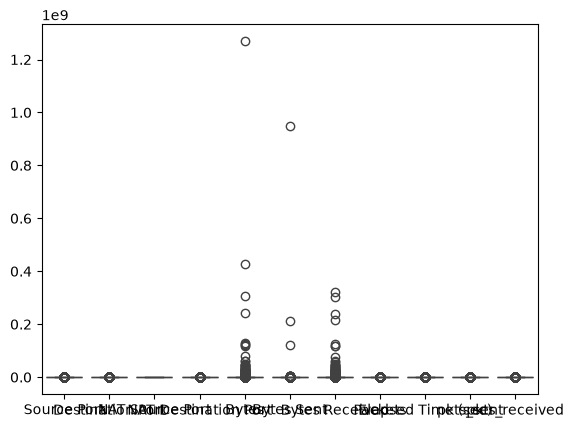

In [11]:
#checking for outliers
sns.boxplot(data=df)

In [12]:
#so we have outliers so we can handle it using IQR method
def fix_outliers_iqr(df):
    num=df.select_dtypes(include='number').columns
    for col in num:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
# Replace outliers with the respective bounds
        df[col] = df[col].apply(lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x)
    return df


In [13]:
df1=fix_outliers_iqr(df)

<Axes: >

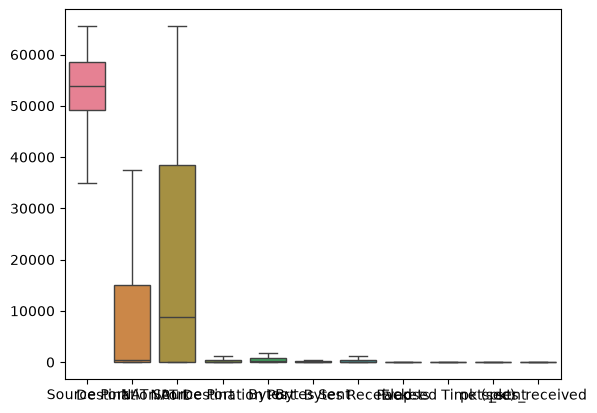

In [14]:
sns.boxplot(data=df1)

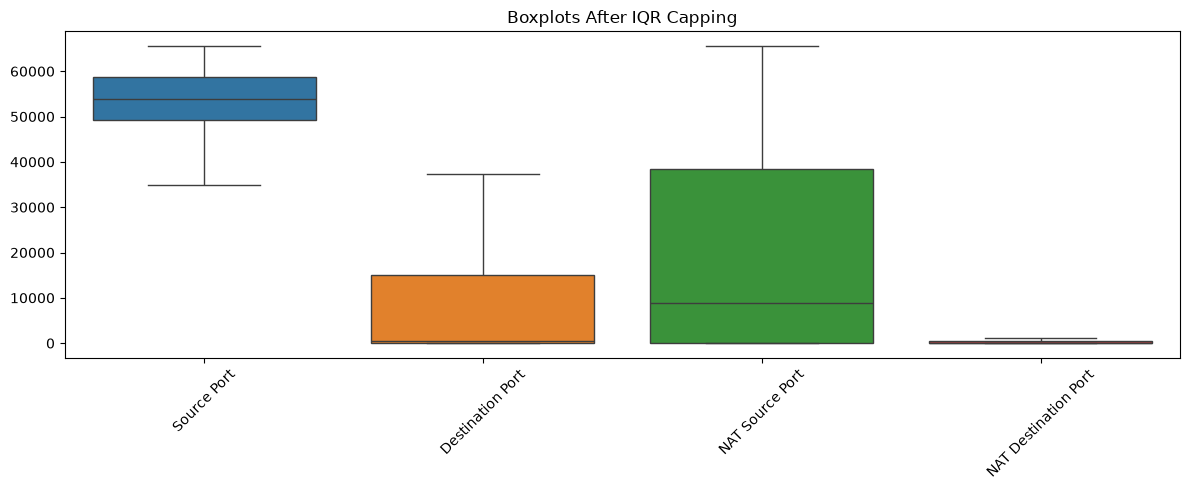

In [15]:
#data visualization using boxplot
boxplot_columns = [
    column for column in ["Source Port","Destination Port","NAT Source Port","NAT Destination Port"]
    if column in df.columns
]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[boxplot_columns])
plt.title("Boxplots After IQR Capping")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
df.columns

Index(['Source Port', 'Destination Port', 'NAT Source Port',
       'NAT Destination Port', 'Action', 'Bytes', 'Bytes Sent',
       'Bytes Received', 'Packets', 'Elapsed Time (sec)', 'pkts_sent',
       'pkts_received'],
      dtype='str')

In [17]:
df['Action_encoded'] = df['Action'].astype('category').cat.codes

In [18]:
# Select numerical columns
num_cols = df.select_dtypes(include=['float']).columns

# Fill missing values before conversion
df[num_cols] = df[num_cols].fillna(0)

# Convert float to integer
df[num_cols] = df[num_cols].astype(int)

# Check data types
print(df.dtypes)

Source Port             int64
Destination Port        int64
NAT Source Port         int64
NAT Destination Port    int64
Action                    str
Bytes                   int64
Bytes Sent              int64
Bytes Received          int64
Packets                 int64
Elapsed Time (sec)      int64
pkts_sent               int64
pkts_received           int64
Action_encoded           int8
dtype: object


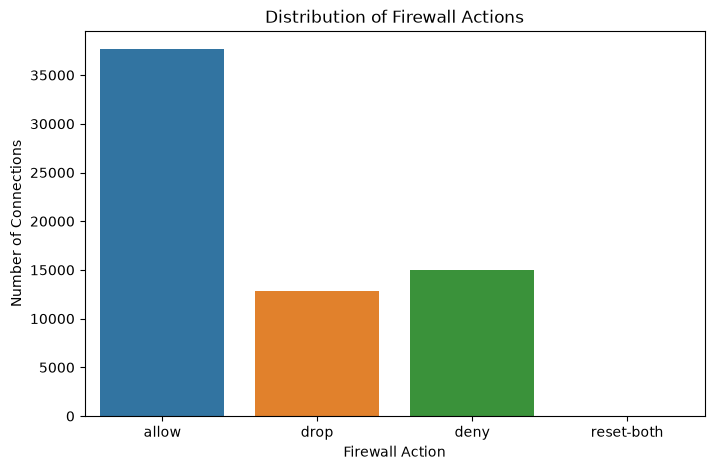

In [19]:
# Data visualization for distribution of the firewall actions: shows how many actions are allowed, denied and dropped

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Action', hue='Action', legend=False)

plt.title('Distribution of Firewall Actions')
plt.xlabel('Firewall Action')
plt.ylabel('Number of Connections')
plt.show()

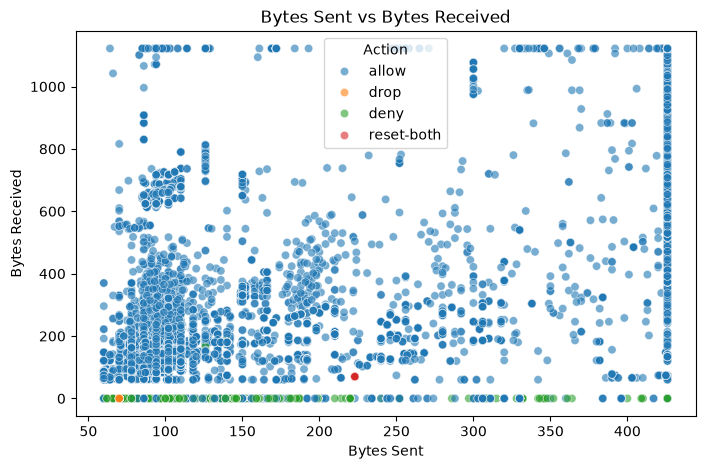

In [20]:
# Data visualization2: Bytes sent VS Bytes recived will helps to understand differences in outgoing and incoming traffic.
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Bytes Sent',
    y='Bytes Received',
    hue='Action',
    alpha=0.6
)

plt.title('Bytes Sent vs Bytes Received')
plt.show()

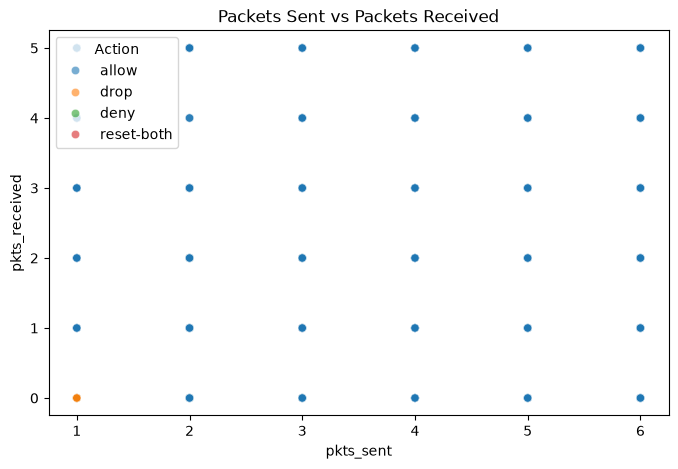

In [21]:
# Data visalization 3: Packet sent vs packets recived helps to identify unusual packet-flow patterns.
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='pkts_sent',
    y='pkts_received',
    hue='Action',
    alpha=0.6
)

plt.title('Packets Sent vs Packets Received')
plt.show()

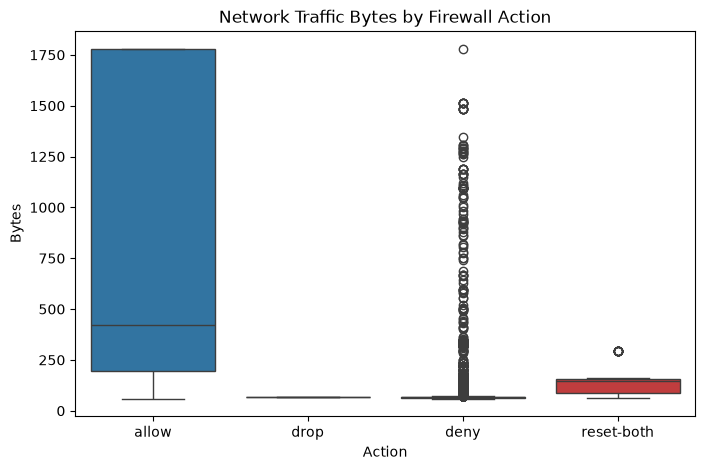

In [22]:
# Data visualization 4: Used to compare network traffic volume across firewall decisions
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df1,
    x='Action',
    y='Bytes',
    hue='Action',
    legend=False
)

plt.title('Network Traffic Bytes by Firewall Action')
plt.show()

In [23]:
target_column = "Action"

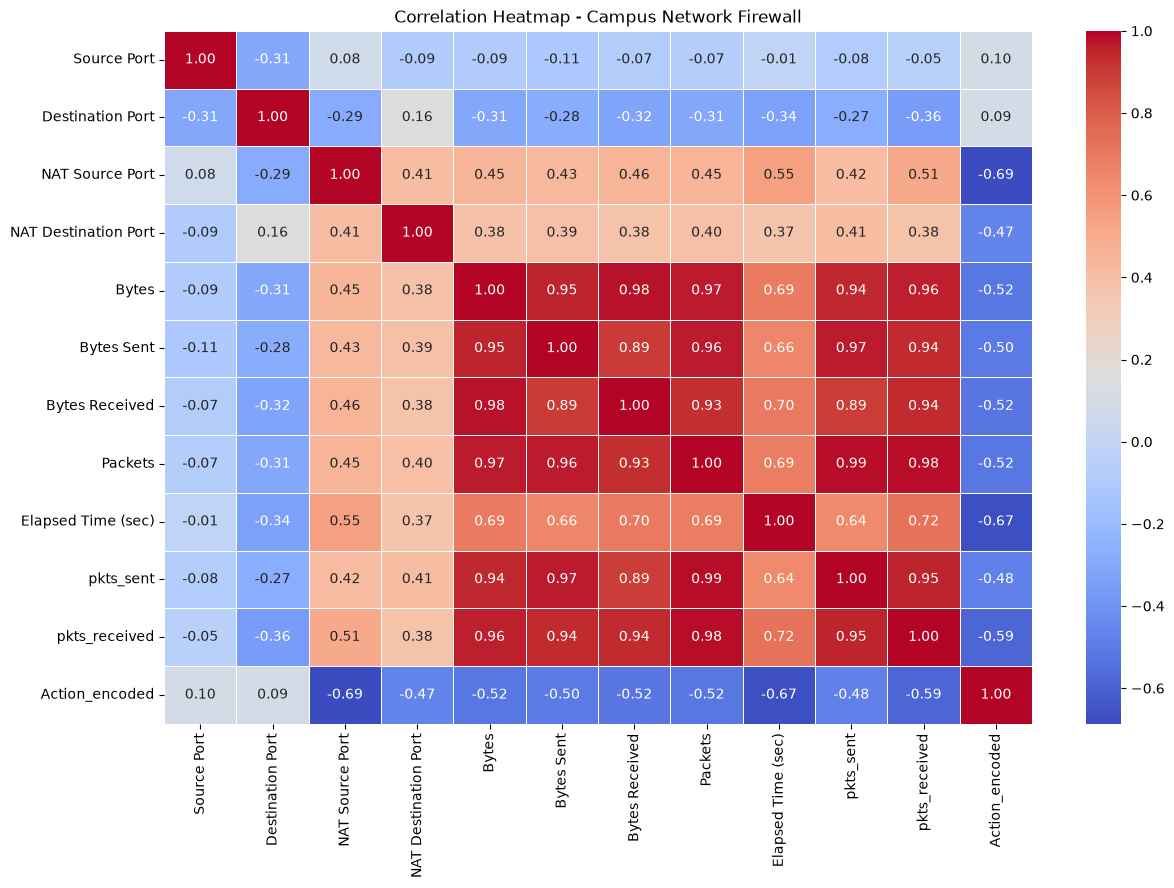

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns only
numerical_df = df.select_dtypes(include=['number'])

# Remove columns that contain only missing values
numerical_df = numerical_df.dropna(axis=1, how='all')

# Create correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(14, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Campus Network Firewall')
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
# Separating independent and dependent variables
X = data.drop('Action', axis=1)
y = data['Action']
RANDOM_STATE = 42

In [26]:
# TRAIN-SPLIT-TEST
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (52425, 11)
Testing features: (13107, 11)

Training target distribution:
Action
allow         0.574
deny          0.229
drop          0.196
reset-both    0.001
Name: proportion, dtype: float64

Testing target distribution:
Action
allow         0.574
deny          0.229
drop          0.196
reset-both    0.001
Name: proportion, dtype: float64


In [27]:
selector = SelectKBest(score_func=f_classif, k=20)
X_new = selector.fit_transform(X, y)

In [28]:
# FEATURE SELECTION FOR Y VARIABLE: LABEL ENCODER
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df['Action'] = le.fit_transform(df['Action'])

print(df['Action'].unique())
from sklearn.preprocessing import LabelEncoder


[0 2 1 3]


In [29]:
df['Action_original'] = df['Action'].copy()

In [30]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Action'] = le.fit_transform(df['Action'].astype(str).str.strip().str.lower())

In [31]:
# Convert only numerical feature columns

In [32]:
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

                 Feature         Score  Selected
2        NAT Source Port  28850.149904      True
1       Destination Port  20333.521688      True
0            Source Port   4597.225456      True
3   NAT Destination Port   1286.792658      True
8     Elapsed Time (sec)    794.717184      True
6         Bytes Received     14.911451      True
10         pkts_received     12.377772      True
7                Packets      6.376157      True
4                  Bytes      4.830297      True
9              pkts_sent      2.549732      True
5             Bytes Sent      0.549729      True


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (52425, 11)
Testing set: (13107, 11)

Training target proportions:
Action
allow         0.574
deny          0.229
drop          0.196
reset-both    0.001
Name: proportion, dtype: float64

Testing target proportions:
Action
allow         0.574
deny          0.229
drop          0.196
reset-both    0.001
Name: proportion, dtype: float64


In [34]:
#Scaling process
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [35]:
# Selecting Algorithm 
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
}

In [36]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [37]:

# Store results
scores = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0
    )
    scores.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "F1 ": round(f1, 4),
        "Recall": round(recall, 4)
    })
# Display results
results_df = pd.DataFrame(scores)
print(results_df)

                 Model  Accuracy  Precision     F1   Recall
0  Logistic Regression    0.9792     0.9795  0.9789  0.9792
1        Decision Tree    0.9977     0.9976  0.9977  0.9977
2        Random Forest    0.9978     0.9978  0.9977  0.9978
